# Week 4 - Part B: smoothing, windows and panel shape, computed

Everything here runs on the **cleaned daily session series** from Part D (parsed explicitly, de-duplicated, −1 sentinels filled and flagged, resampled to daily with `sum()`, 13 outage days left as NaN, extract ends 11 Sep 2025).
Run `partD_ecommerce_figure.ipynb` first, it writes `data/clean/sessions_daily_clean.csv`.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.seasonal import seasonal_decompose

try:
    ROOT = Path(__file__).resolve().parents[1]
    IN_NOTEBOOK = False
except NameError:
    ROOT = Path.cwd()
    IN_NOTEBOOK = True
sys.path.insert(0, str(ROOT))


def show():
    """Inline in the notebook; as a script just close the figure (the PNG is already saved)."""
    if IN_NOTEBOOK:
        plt.show()
    else:
        plt.close("all")


import tslib
from vizlib import PALETTE, save_fig, style_defaults

DATA = ROOT / "data"
CHARTS = ROOT / "charts"
SUB = ROOT / "submission"
CHARTS.mkdir(exist_ok=True)
SUB.mkdir(exist_ok=True)
style_defaults()
warnings.filterwarnings("ignore")
BLUE, ORANGE, GREEN = PALETTE["series"]
PINK, GREY, INK, SOFT = PALETTE["series_4th"], PALETTE["muted"], PALETTE["ink"], PALETTE["ink_soft"]
NOTE = "Source: synthetic course data, CDB601220 Week 4 (sessions_hourly.csv, cleaned in Part D). Chart: Syed Sami Ullah."

OUT = []                      # everything printed also goes to partB_output.txt
def say(*a):
    line = " ".join(str(x) for x in a)
    print(line)
    OUT.append(line)

clean_path = DATA / "clean" / "sessions_daily_clean.csv"
if not clean_path.exists():
    raise FileNotFoundError("Run partD_ecommerce_figure first - it writes data/clean/sessions_daily_clean.csv")
s = pd.read_csv(clean_path, parse_dates=["date"], index_col="date").sessions.asfreq("D")
a = tslib.audit_index(s.dropna(), "D")
say("Part B - cleaned daily sessions")
say(f"days {len(s)}, recorded {s.notna().sum()}, missing {s.isna().sum()}, duplicated {a['n_duplicated']}, sorted {a['monotonic']}, span {s.index.min().date()} to {s.index.max().date()}")

Part B - cleaned daily sessions
days 529, recorded 516, missing 13, duplicated 0, sorted True, span 2024-04-01 to 2025-09-11


## Q1 · The window is a hypothesis (4 marks)

In [2]:
wr = tslib.window_report(s, (7, 28, 91))
cycles = {7: "the weekly cycle (exactly one Mon-Sun)", 28: "the weekly cycle (four whole weeks) plus ~monthly wiggles",
          91: "weekly + monthly, and most of the seasonal swing (13 weeks, a quarter)"}
wr["cycle removed"] = wr.window.map(cycles)
say("\nQ1 window_report")
say(wr.to_string(index=False))


Q1 window_report
 window    raw_sd  smoothed_sd  variation_removed_pct  periods_lost_each_end                                                          cycle removed
      7 6840.9138    4727.2795                   30.9                      3                                 the weekly cycle (exactly one Mon-Sun)
     28 6840.9138    4522.7532                   33.9                     14              the weekly cycle (four whole weeks) plus ~monthly wiggles
     91 6840.9138    4233.4941                   38.1                     45 weekly + monthly, and most of the seasonal swing (13 weeks, a quarter)


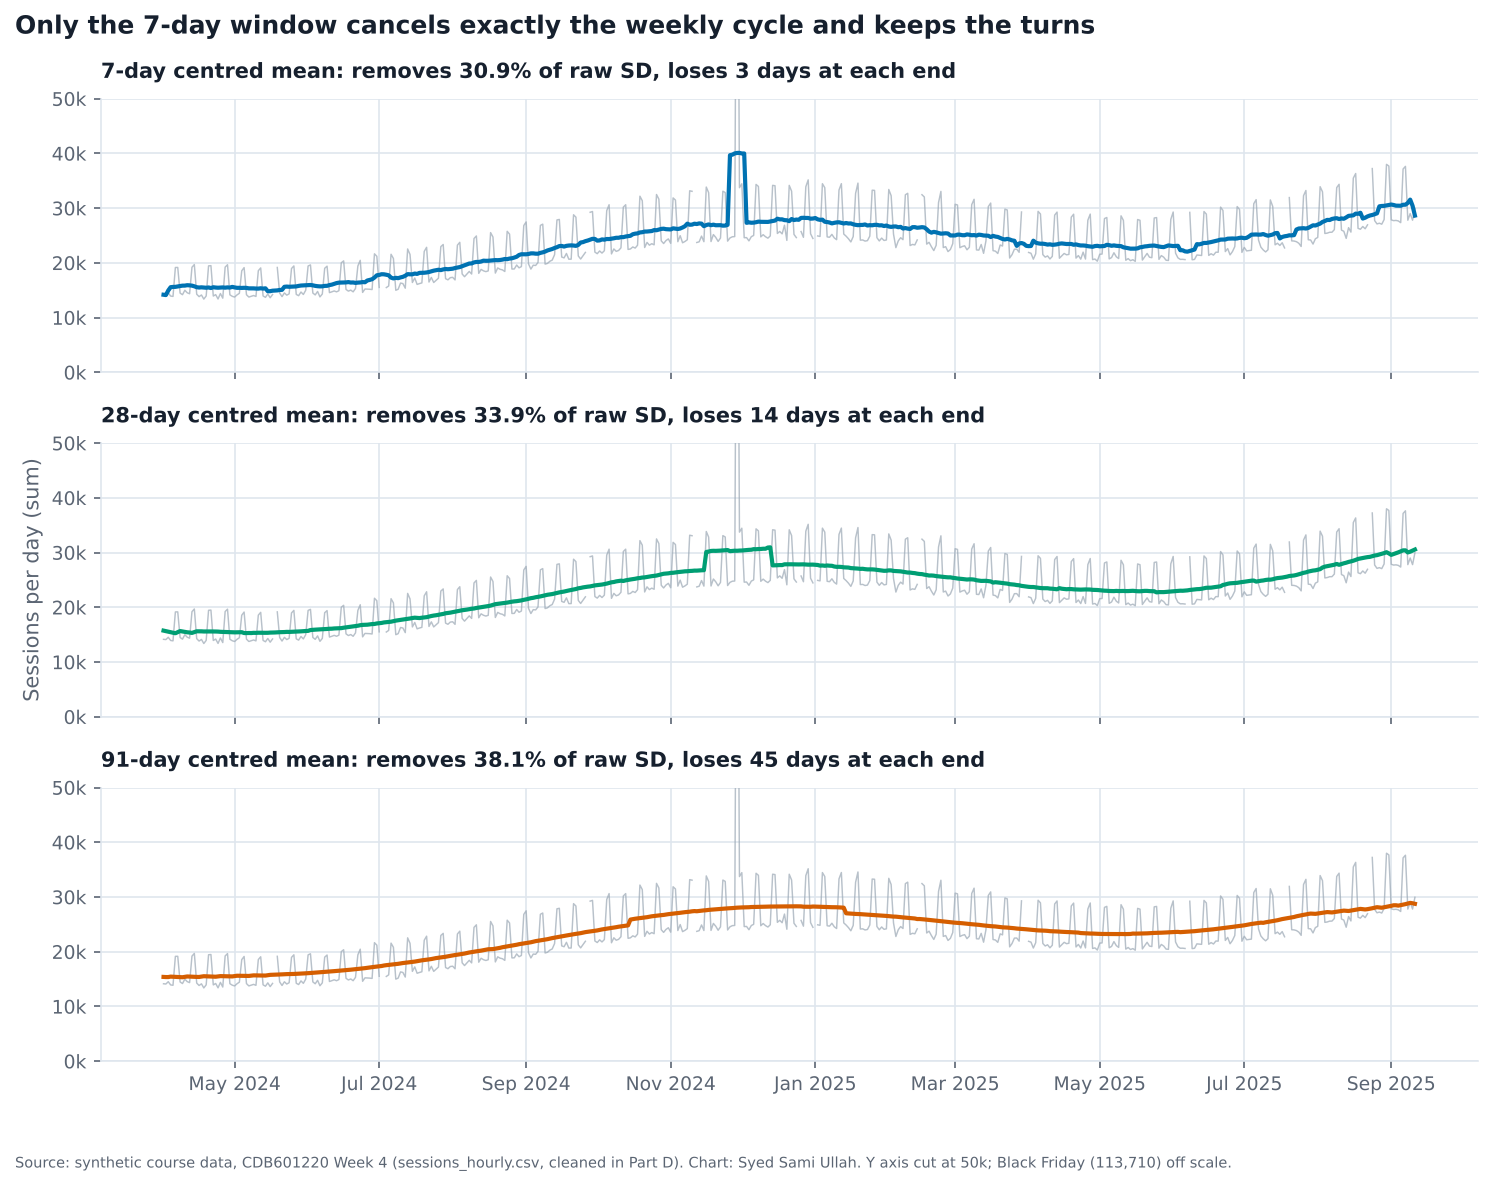

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True, sharey=True)
for ax, w, col in zip(axes, (7, 28, 91), (BLUE, GREEN, ORANGE)):
    r = s.rolling(w, center=True, min_periods=max(2, w // 2)).mean()
    ax.plot(s.index, s, color=GREY, lw=0.7, alpha=0.7)
    ax.plot(r.index, r, color=col, lw=2)
    row = wr.set_index("window").loc[w]
    ax.set_title(f"{w}-day centred mean: removes {row.variation_removed_pct:.1f}% of raw SD, loses {row.periods_lost_each_end} days at each end", fontsize=10)
    ax.set_ylim(0, 50000)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k"))
axes[1].set_ylabel("Sessions per day (sum)")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.suptitle("Only the 7-day window cancels exactly the weekly cycle and keeps the turns", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, CHARTS / "partB_q1_windows.png", note=NOTE + " Y axis cut at 50k; Black Friday (113,710) off scale.")
show()

**What this chart shows.** The 7-day line removes the weekend teeth and nothing else, so the winter high and the spring low are still sharp. The 91-day line flattens the turns and blurs the timing of the spring low by weeks.

**My choice: 7 days.** The thing hiding the trend on the Monday dashboard is the weekend rhythm (Sat-Sun run about +35%), and that cycle is exactly 7 days long. A 7-day centred window holds every weekday once, so it cancels the cycle completely and only costs 3 days at each end. The "% removed" column is not the reason, since 28 and 91 remove more variation but also remove signal (the seasonal turn) that leadership needs to see. The SD column barely moves between windows because most of the raw SD is the trend itself and Black Friday, not the weekly noise.

## Q2 · Three smoothers against one spike (3 marks)

In [4]:
bf = pd.Timestamp("2024-11-29")
mean14 = s.rolling(14, center=True, min_periods=14).mean()
med14 = s.rolling(14, center=True, min_periods=14).median()
ewma14 = s.ewm(span=14, ignore_na=True).mean()
fortnight_med = s[bf - pd.Timedelta(days=7): bf + pd.Timedelta(days=7)].drop(bf).median()
say("\nQ2 at Black Friday 2024-11-29")
say(f"raw {s[bf]:,.0f} | fortnight median (excl. the day) {fortnight_med:,.0f}")
say(f"14-day centred mean   {mean14[bf]:,.0f}  ({mean14[bf] / fortnight_med - 1:+.0%} vs normal)")
say(f"14-day centred median {med14[bf]:,.0f}  ({med14[bf] / fortnight_med - 1:+.0%})")
say(f"EWMA (span 14)        {ewma14[bf]:,.0f}  ({ewma14[bf] / fortnight_med - 1:+.0%})")
say(f"days the 14-day mean stays >10% above the median around BF: {int(((mean14 / med14 - 1) > 0.10)['2024-11-01':'2024-12-31'].sum())}")


Q2 at Black Friday 2024-11-29
raw 113,710 | fortnight median (excl. the day) 24,780
14-day centred mean   33,468  (+35% vs normal)
14-day centred median 24,780  (+0%)
EWMA (span 14)        38,029  (+53%)
days the 14-day mean stays >10% above the median around BF: 17


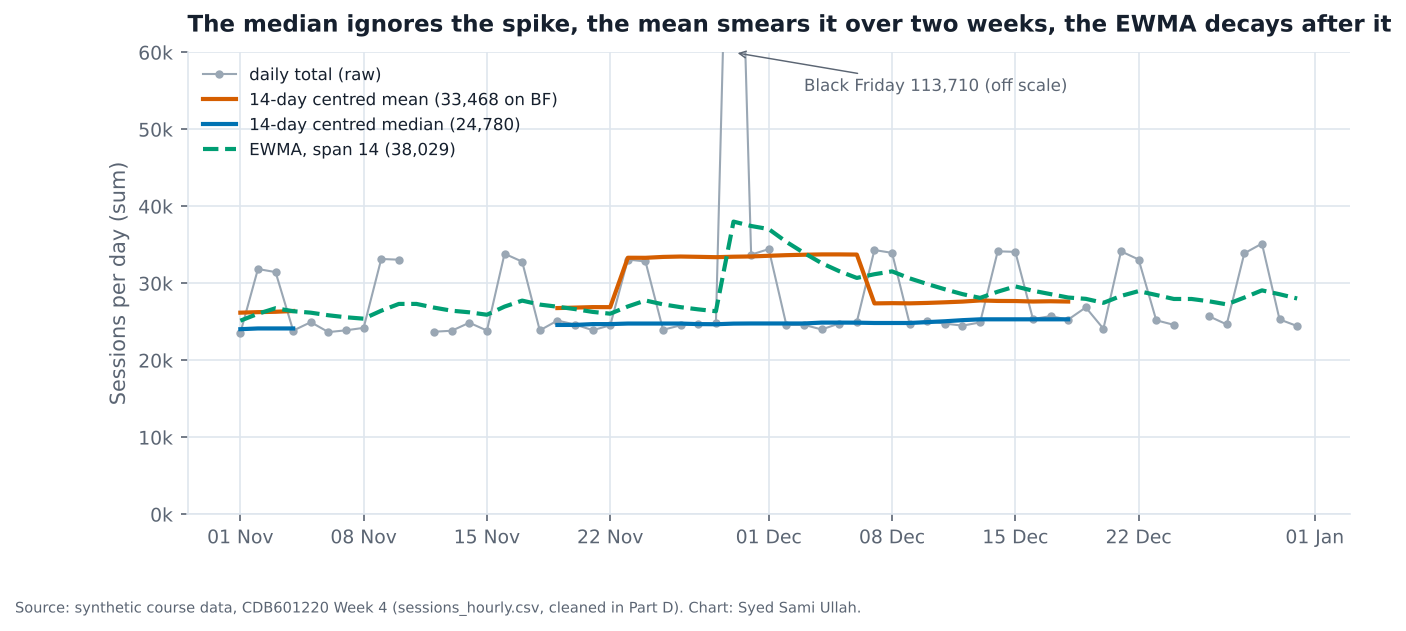

In [5]:
z = slice("2024-11-01", "2024-12-31")
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(s[z].index, s[z], color=GREY, lw=1, marker="o", markersize=3, label="daily total (raw)")
ax.plot(mean14[z].index, mean14[z], color=ORANGE, lw=2, label=f"14-day centred mean ({mean14[bf]:,.0f} on BF)")
ax.plot(med14[z].index, med14[z], color=BLUE, lw=2, label=f"14-day centred median ({med14[bf]:,.0f})")
ax.plot(ewma14[z].index, ewma14[z], color=GREEN, lw=2, ls="--", label=f"EWMA, span 14 ({ewma14[bf]:,.0f})")
ax.set_ylim(0, 60000)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k"))
ax.annotate("Black Friday 113,710 (off scale)", xy=(bf, 60000), xytext=(bf + pd.Timedelta(days=4), 55000), fontsize=8, color=SOFT,
            arrowprops=dict(arrowstyle="->", color=SOFT, lw=0.7))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.set_ylabel("Sessions per day (sum)")
ax.legend(loc="upper left", fontsize=8)
ax.set_title("The median ignores the spike, the mean smears it over two weeks, the EWMA decays after it", fontsize=11)
save_fig(fig, CHARTS / "partB_q2_smoothers.png", note=NOTE)
show()

**What this chart shows.** One day at 4.6× normal lifts the 14-day mean to about 33k for two whole weeks, a "trend" that never happened. The median stays on the real level (~24.8k), and the EWMA jumps and then fades because it only looks backwards.

**Which where.** A *monitoring dashboard* should use the **EWMA**: it needs no future days so it can be drawn every morning, and it reacts to a spike quickly. A *quarterly report* should use the **centred median**, because one promo day should not bend a quarter's trend line (the spike itself gets reported as an event, not hidden).

## Q3 · Decompose it (3 marks)

In [6]:
s_filled = s.interpolate(method="time")       # seasonal_decompose cannot take NaN: 13 outage days linearly filled FOR THIS STEP ONLY
dec = seasonal_decompose(s_filled, model="additive", period=7)
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekly = dec.seasonal.groupby(dec.seasonal.index.dayofweek).first()
amp = weekly.max() - weekly.min()
top_res = dec.resid.abs().nlargest(3)
say("\nQ3 seasonal_decompose(additive, period=7)  [13 outage days linearly interpolated for this step only]")
say("weekly seasonal by day (Mon..Sun):", weekly.round(0).astype(int).tolist())
say(f"peak-to-trough amplitude: {amp:,.0f} sessions/day (high {DAYS[weekly.idxmax()]}, low {DAYS[weekly.idxmin()]})")
say(f"largest residual: {top_res.index[0].date()}  ({dec.resid[top_res.index[0]]:+,.0f}); next: {top_res.index[1].date()} ({dec.resid[top_res.index[1]]:+,.0f})")
try:
    seasonal_decompose(s_filled, model="additive", period=365)
    say("period=365 ran")
except ValueError as e:
    say(f"period=365 -> ValueError: {e}")


Q3 seasonal_decompose(additive, period=7)  [13 outage days linearly interpolated for this step only]
weekly seasonal by day (Mon..Sun): [-2238, -2327, -2332, -2334, -992, 4973, 5250]
peak-to-trough amplitude: 7,584 sessions/day (high Sun, low Thu)
largest residual: 2024-11-29  (+74,611); next: 2024-12-02 (-13,154)
period=365 -> ValueError: x must have 2 complete cycles requires 730 observations. x only has 529 observation(s)


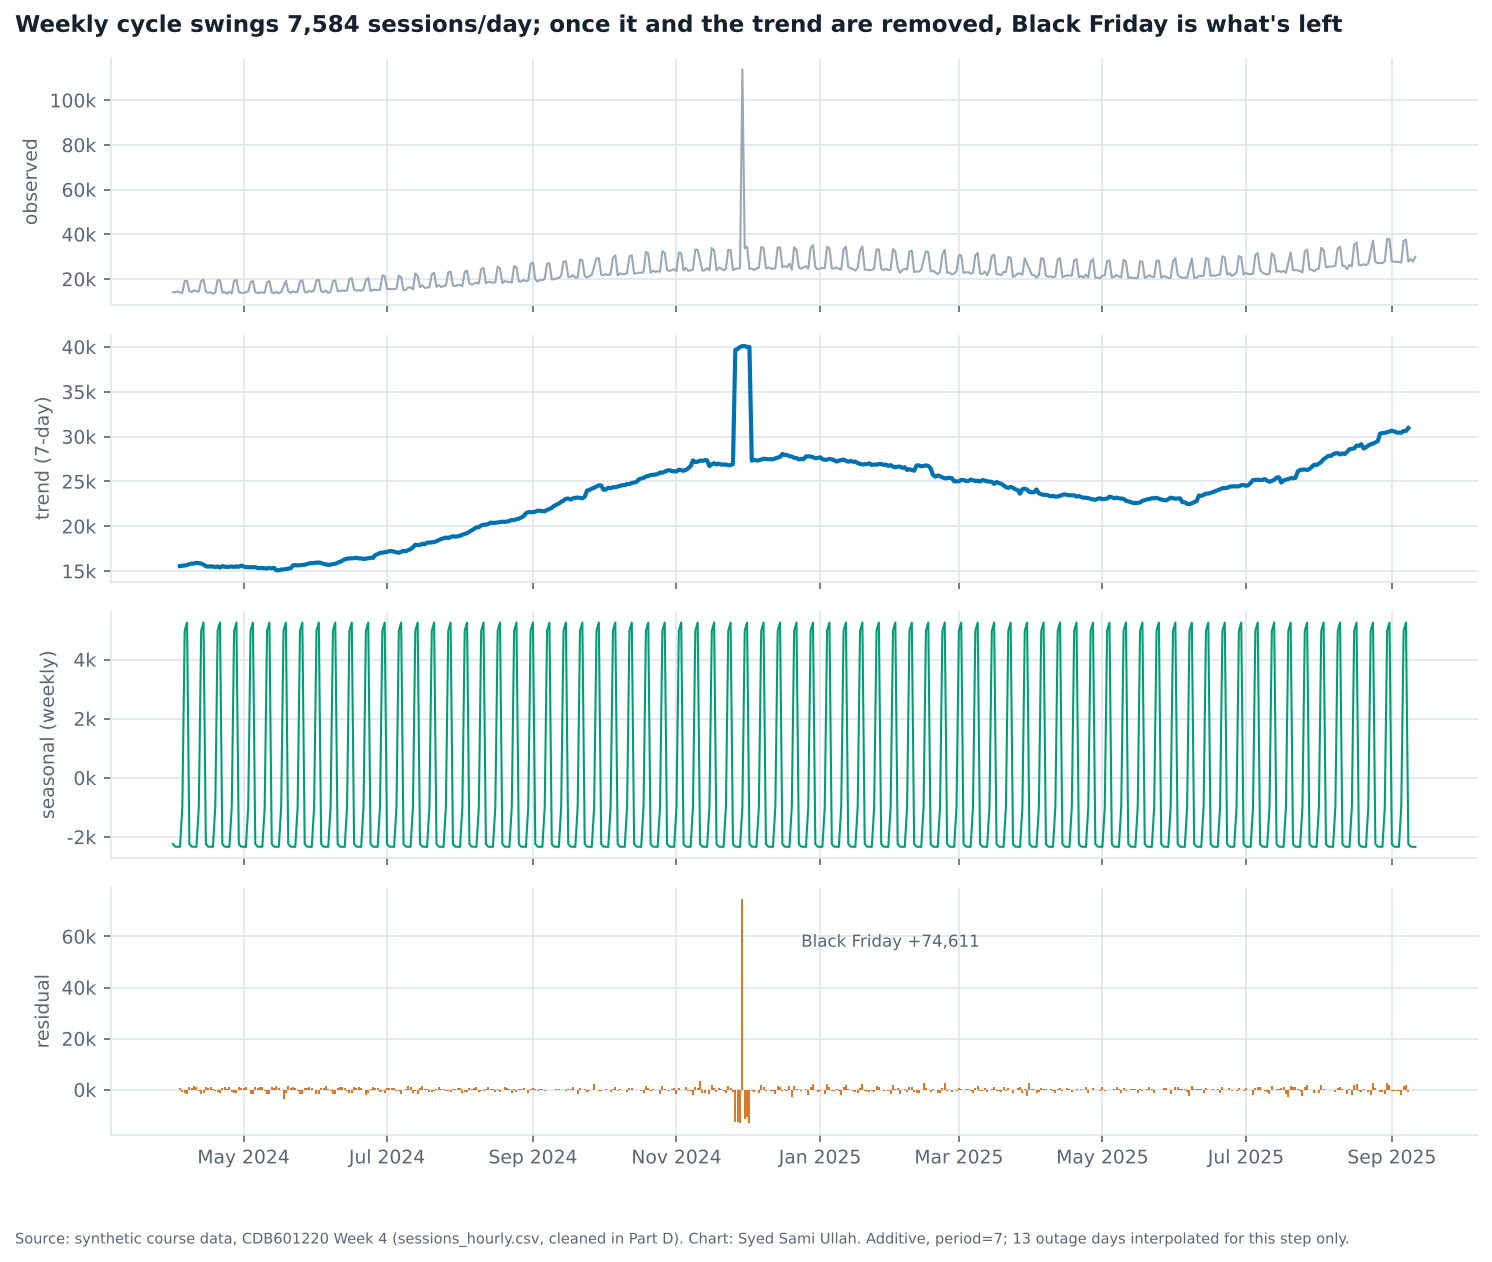

In [7]:
fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
parts = [("observed", dec.observed, GREY), ("trend (7-day)", dec.trend, BLUE), ("seasonal (weekly)", dec.seasonal, GREEN), ("residual", dec.resid, ORANGE)]
for ax, (name, ser, col) in zip(axes, parts):
    if name == "residual":
        ax.vlines(ser.index, 0, ser, color=col, lw=0.8)
        ax.annotate(f"Black Friday {dec.resid[bf]:+,.0f}", xy=(bf, dec.resid[bf]), xytext=(bf + pd.Timedelta(days=25), dec.resid[bf] * 0.75),
                    fontsize=8, color=SOFT)
    else:
        ax.plot(ser.index, ser, color=col, lw=1 if name != "trend (7-day)" else 2)
    ax.set_ylabel(name, fontsize=9)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k"))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.suptitle(f"Weekly cycle swings {amp:,.0f} sessions/day; once it and the trend are removed, Black Friday is what's left",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()
save_fig(fig, CHARTS / "partB_q3_decompose.png", note=NOTE + " Additive, period=7; 13 outage days interpolated for this step only.")
show()

**What this chart shows.** The weekly component is flat Mon-Thu, a little higher on Friday, and then a weekend jump of about 7,600 sessions a day. The residual is quiet apart from one huge spike on 29 November 2024 (Black Friday, +74,611), which is exactly the event worth investigating. The smaller late-November residuals around it are the 7-day trend being pulled up by that one day.

**period=365.** It does not run: `seasonal_decompose` needs two full cycles (730 days) and this extract has 529. If it did, the things that repeat once a year (the Black Friday / year-end season and the spring slump) would move out of `resid` and `trend` into `seasonal`, and Black Friday would stop looking like a one-off anomaly. With only one autumn in the data, that would be a guess, not a measurement.

## Q4 · Trailing or centred (2 marks)

In [8]:
lag_all = tslib.lag_at_turn(s_filled, 31, how="min")
lag_25 = tslib.lag_at_turn(s_filled["2025-01-01":], 31, how="min")
say("\nQ4 lag_at_turn, 31-day window")
for name, lg in [("whole series (minimum is the start of the series)", lag_all), ("the 2025 spring turn", lag_25)]:
    say(f"{name}: trailing {lg['trailing_turn'].date()}, centred {lg['centred_turn'].date()}, lag {lg['lag_periods']} days vs half-window {lg['half_window']}")


Q4 lag_at_turn, 31-day window
whole series (minimum is the start of the series): trailing 2024-05-22, centred 2024-05-07, lag 15 days vs half-window 15
the 2025 spring turn: trailing 2025-06-11, centred 2025-05-27, lag 15 days vs half-window 15


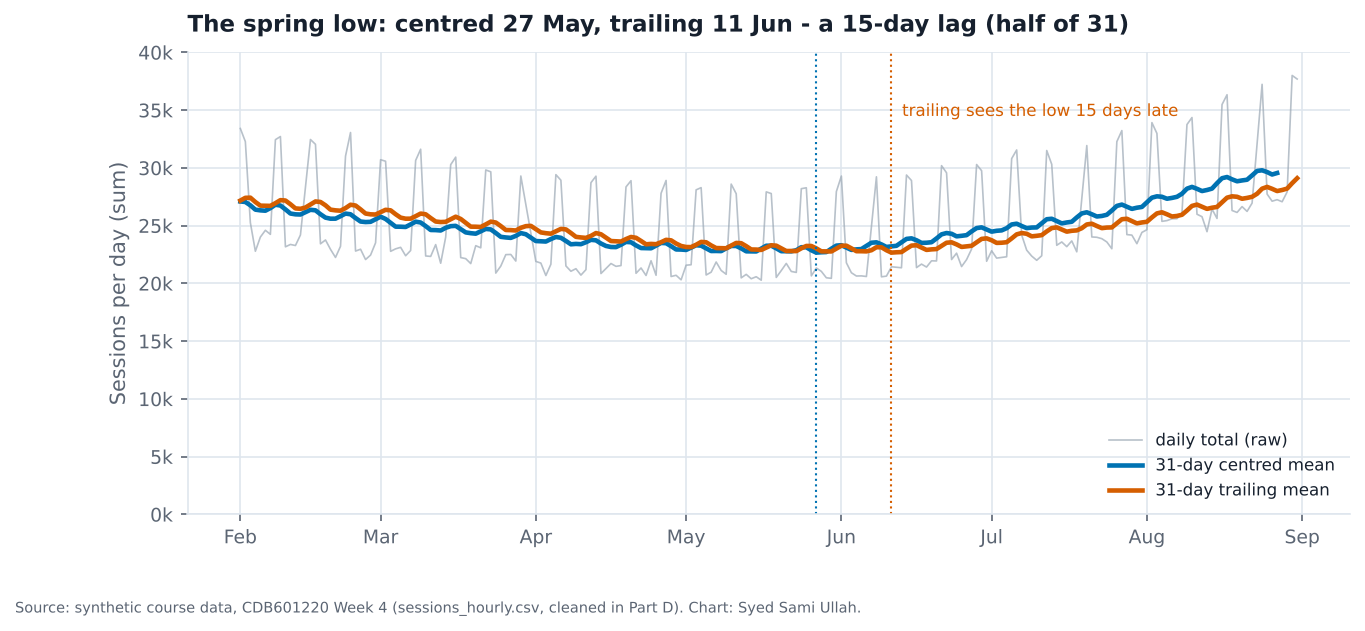

In [9]:
z = s_filled["2025-02-01":"2025-08-31"]
tr = s_filled.rolling(31).mean()[z.index]
ce = s_filled.rolling(31, center=True).mean()[z.index]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(z.index, z, color=GREY, lw=0.8, alpha=0.7, label="daily total (raw)")
ax.plot(ce.index, ce, color=BLUE, lw=2.2, label="31-day centred mean")
ax.plot(tr.index, tr, color=ORANGE, lw=2.2, label="31-day trailing mean")
ax.axvline(lag_25["centred_turn"], color=BLUE, lw=1, ls=":")
ax.axvline(lag_25["trailing_turn"], color=ORANGE, lw=1, ls=":")
ax.text(lag_25["trailing_turn"], 34500, f"  trailing sees the low {lag_25['lag_periods']} days late", color=ORANGE, fontsize=8)
ax.set_ylim(0, 40000)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k"))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_ylabel("Sessions per day (sum)")
ax.legend(loc="lower right", fontsize=8)
ax.set_title(f"The spring low: centred {lag_25['centred_turn']:%d %b}, trailing {lag_25['trailing_turn']:%d %b} - a {lag_25['lag_periods']}-day lag (half of 31)", fontsize=11)
save_fig(fig, CHARTS / "partB_q4_trailing_vs_centred.png", note=NOTE)
show()

**What this chart shows.** Both lines find the same low, but the trailing one finds it 15 days later, which is exactly half the window, as the arithmetic says it should.

**The live dashboard must show the trailing mean**, because a centred mean needs 15 days that haven't happened yet (its last 15 points would be blank or quietly computed on a shorter window). The caption has to say so: *"31-day trailing mean: each point averages the 31 days up to and including that date, so turning points appear about 15 days after they happen."*

## Q5 · The window is a claim (3 marks)
12 start months (Apr 2024 - Mar 2025) × 5 window lengths. Each "window" is the slice of `w` days starting on the 1st of that month, and I fit a least-squares line to the daily totals inside it (outage days dropped, not filled).

In [10]:
rows = []
for start in pd.date_range("2024-04-01", "2025-03-01", freq="MS"):
    for w in (7, 14, 28, 56, 91):
        seg = s[start: start + pd.Timedelta(days=w - 1)].dropna()
        slope = np.polyfit((seg.index - seg.index[0]).days, seg.values, 1)[0]
        rows.append({"start": start, "window": w, "slope_per_day": slope, "n_days": len(seg)})
grid = pd.DataFrame(rows)
n_up, n_down = int((grid.slope_per_day > 0).sum()), int((grid.slope_per_day < 0).sum())
say(f"\nQ5 {len(grid)} start x window combinations: RISING {n_up}, FALLING {n_down}")
piv = grid.pivot(index="start", columns="window", values="slope_per_day")
piv.index = piv.index.strftime("%b %Y")
say(piv.round(0).to_string())


Q5 60 start x window combinations: RISING 34, FALLING 26
window        7      14     28    56     91
start                                      
Apr 2024   875.0  257.0   48.0   6.0   17.0
May 2024   170.0   28.0   16.0  28.0   44.0
Jun 2024  -955.0 -187.0  -20.0  40.0   58.0
Jul 2024  1004.0  282.0  125.0  87.0   85.0
Aug 2024   -82.0   72.0   58.0  76.0   79.0
Sep 2024   -26.0   97.0  103.0  81.0  129.0
Oct 2024   876.0  266.0  136.0  71.0   69.0
Nov 2024  -782.0 -121.0  -26.0  22.0  -24.0
Dec 2024    23.0   11.0   27.0 -11.0  -27.0
Jan 2025   -62.0   -2.0  -30.0 -36.0  -44.0
Feb 2025 -1575.0 -448.0 -154.0 -70.0  -52.0
Mar 2025 -1414.0 -334.0 -126.0 -63.0  -36.0


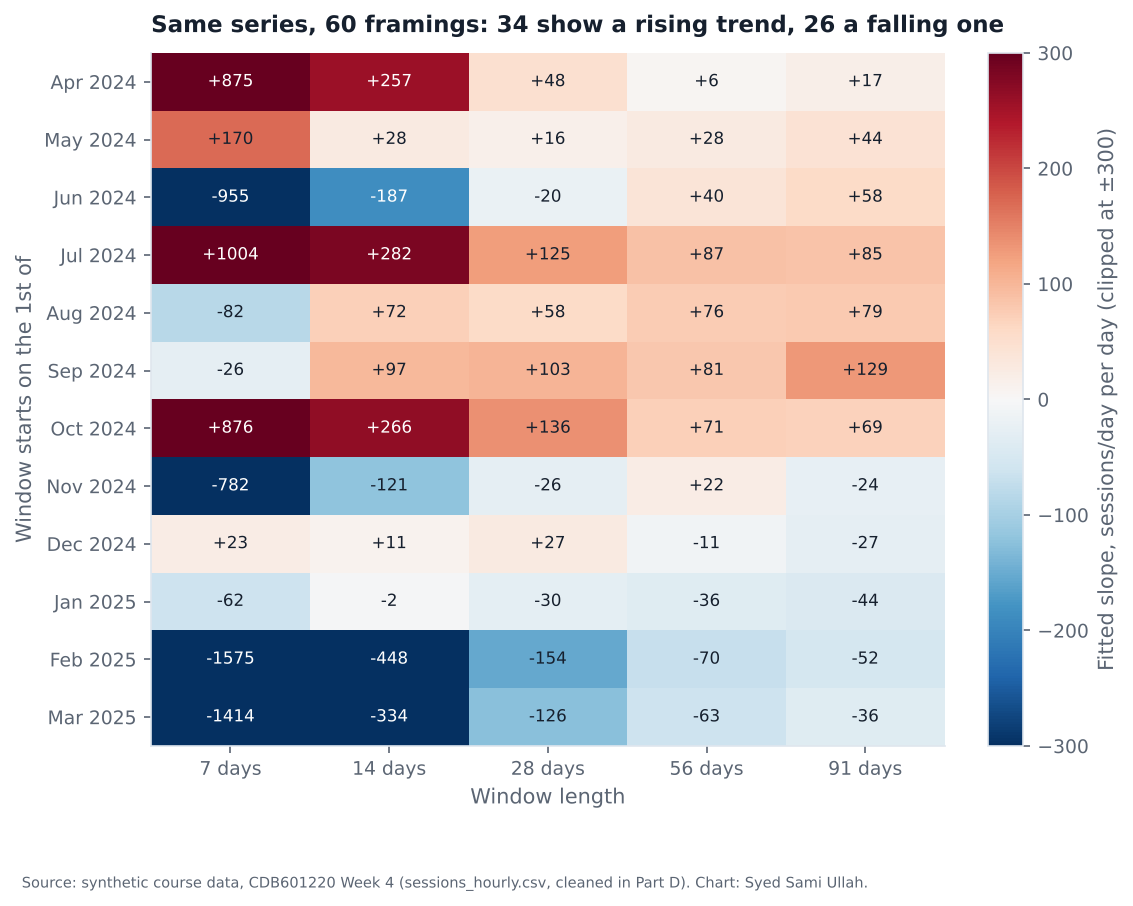

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 6))
lim = 300
im = ax.imshow(piv.clip(-lim, lim).values, cmap=PALETTE["diverging"], vmin=-lim, vmax=lim, aspect="auto")
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        ax.text(j, i, f"{v:+.0f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 180 else INK)
ax.set_xticks(range(5))
ax.set_xticklabels([f"{w} days" for w in piv.columns])
ax.set_yticks(range(12))
ax.set_yticklabels(piv.index)
ax.set_xlabel("Window length")
ax.set_ylabel("Window starts on the 1st of")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.04)
cb.set_label("Fitted slope, sessions/day per day (clipped at ±300)", color=SOFT)
ax.set_title(f"Same series, 60 framings: {n_up} show a rising trend, {n_down} a falling one", fontsize=11)
save_fig(fig, CHARTS / "partB_q5_window_claims.png", note=NOTE)
show()

**What this chart shows.** Depending only on where the window starts and how long it is, the same unchanged series "rises" in 34 framings and "falls" in 26. Short windows flip sign month to month (they mostly measure where the weekend falls), all 15 windows starting in Jan-Mar 2025 slope down, and almost everything starting Jul-Oct 2024 slopes up.

**Why there's no Lie Factor here.** Tufte's Lie Factor is (effect shown) / (effect in the data), and it assumes there is one true "effect in the data" to divide by. A cherry-picked window doesn't distort the ink, it chooses which effect gets measured, and the grid above shows the effect itself changes sign with the window. With no single denominator, the ratio is undefined. The honest substitute is to **show the whole distribution of framings** (this grid, or "34 of 60 combinations rise"), fix the window from the cycle before looking (Q1), start at the first recorded day, and report a second window as a robustness check (the 28-day appendix in Part D).

In [12]:
(SUB / "partB_output.txt").write_text("\n".join(OUT) + "\n", encoding="utf-8")
print("wrote submission/partB_output.txt")

wrote submission/partB_output.txt
